In [3]:
import cv2
import numpy as np

# Загрузка изображения
image = cv2.imread('images/balloon.jpg')

# Применение простого размытия с ядром 5x5
blurred = cv2.blur(image, (5, 5))

# Сравнение результатов
cv2.imshow('Original', image)
cv2.imshow('Average Blur', blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [5]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2.imshow('gray', gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

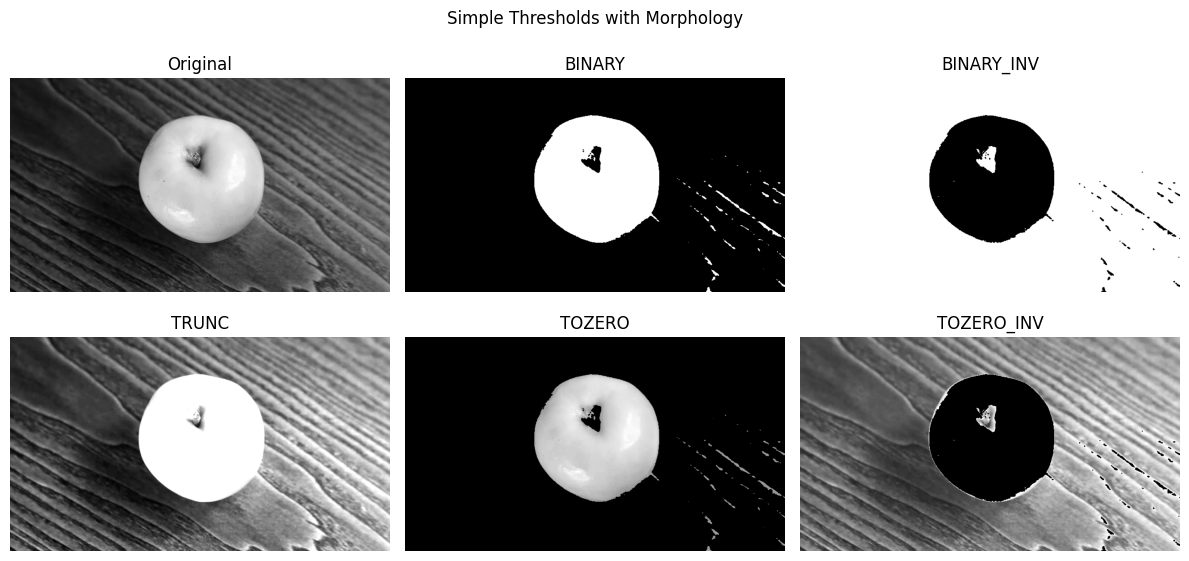

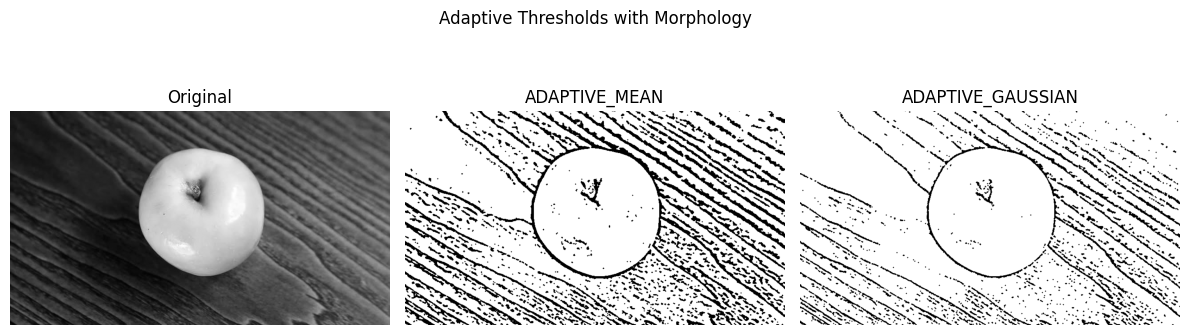

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Параметры, которые можно менять
# =========================
threshold_value = 146      # пороговое значение для простых методов
adaptive_block_size = 13      # размер окна для адаптивного порога (должен быть нечетным)
adaptive_C = 4              # константа для адаптивного порога
morph_kernel_size = 3         # ядро для морфологии

# =========================
# Загрузка и подготовка
# =========================
image = cv2.imread('images/apple.png')
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Ядро для морфологии
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (morph_kernel_size, morph_kernel_size))


ret, th_binary = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY)
th_binary = cv2.morphologyEx(th_binary, cv2.MORPH_CLOSE, kernel)

ret, th_binary_inv = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY_INV)
th_binary_inv = cv2.morphologyEx(th_binary_inv, cv2.MORPH_CLOSE, kernel)

ret, th_trunc = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_TRUNC)
th_trunc = cv2.morphologyEx(th_trunc, cv2.MORPH_CLOSE, kernel)

ret, th_tozero = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_TOZERO)
th_tozero = cv2.morphologyEx(th_tozero, cv2.MORPH_CLOSE, kernel)

ret, th_tozero_inv = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_TOZERO_INV)
th_tozero_inv = cv2.morphologyEx(th_tozero_inv, cv2.MORPH_CLOSE, kernel)

simple_thresholds = [gray, th_binary, th_binary_inv, th_trunc, th_tozero, th_tozero_inv]
simple_titles = ['Original', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']


adaptive_mean = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY, adaptive_block_size, adaptive_C
)
adaptive_mean = cv2.morphologyEx(adaptive_mean, cv2.MORPH_CLOSE, kernel)

adaptive_gauss = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, adaptive_block_size, adaptive_C
)
adaptive_gauss = cv2.morphologyEx(adaptive_gauss, cv2.MORPH_CLOSE, kernel)

adaptive_thresholds = [gray, adaptive_mean, adaptive_gauss]
adaptive_titles = ['Original', 'ADAPTIVE_MEAN', 'ADAPTIVE_GAUSSIAN']

# =========================
# Визуализация простых порогов
# =========================
plt.figure(figsize=(12, 6))
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(simple_thresholds[i], cmap='gray')
    plt.title(simple_titles[i])
    plt.axis('off')
plt.suptitle('Simple Thresholds with Morphology')
plt.tight_layout()
plt.show()

# =========================
# Визуализация адаптивных порогов
# =========================
plt.figure(figsize=(12, 4))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(adaptive_thresholds[i], cmap='gray')
    plt.title(adaptive_titles[i])
    plt.axis('off')
plt.suptitle('Adaptive Thresholds with Morphology')
plt.tight_layout()
plt.show()
